In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# load dataset
df = pd.read_csv('StudentsPerformance.csv')
print("Dataset loaded successfully!")

Dataset loaded successfully!


# Inspect structure,Dimension,Columns,Data Types

In [34]:
print("----SHAPE----")
print(f"Row: {df.shape[0]},Columns:{df.shape[1]}")


----SHAPE----
Row: 1000,Columns:8


In [35]:
print("\n---COLUMNS----")
print(df.columns.tolist())


---COLUMNS----
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']


In [36]:
print("\n----DATA TYPES----")
print(df.dtypes)


----DATA TYPES----
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object


In [37]:
print("\n----INFO----")
df.info()


----INFO----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [38]:
print("\n----STATISTICS----")
df.describe()


----STATISTICS----


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


# Inspect Categorial vs Numerical

In [39]:
# Demographic attributes and score variables
cat_cols = ['gender','race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
num_cols = ['math score', 'reading score', ' writing score']

print("Categorial Columns Value Counts:")
for col in cat_cols:
    print (f"\n{col}:")
    print(df[col].value_counts())

Categorial Columns Value Counts:

gender:
gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity:
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education:
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch:
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test preparation course:
test preparation course
none         642
completed    358
Name: count, dtype: int64


# Handle Missing Values

In [42]:
import pandas as pd

df = pd.read_csv("studentsPerformance.csv")

print("Missing values before:")
print(df.isnull().sum())

num_cols = df.select_dtypes(include=['number']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].mean())

print("Missing values after:")
print(df.isnull().sum())

Missing values before:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Missing values after:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


# Handle Duplicate Records

In [43]:

print(f"Duplicates found:{df.duplicated().sum()}")
df =df.drop_duplicates()
print(f"Shape after removing duplicates:{df.shape}")

Duplicates found:0
Shape after removing duplicates:(1000, 8)


# Clean  Categorial Features

In [44]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Values:")
print(df.duplicated().sum())

Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
Duplicate Values:
0


# Analyse Math,Reading, Writing, Scores- Central Tendency & Dispersion

--- Mean ---
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

--- Median ---
math score       66.0
reading score    70.0
writing score    69.0
dtype: float64

--- Standard Deviation ---
math score       15.163080
reading score    14.600192
writing score    15.195657
dtype: float64

--- Quartiles ---
      math score  reading score  writing score
0.25        57.0           59.0          57.75
0.50        66.0           70.0          69.00
0.75        77.0           79.0          79.00
Index(['math score', 'reading score', 'writing score'], dtype='object')


<Figure size 640x480 with 0 Axes>

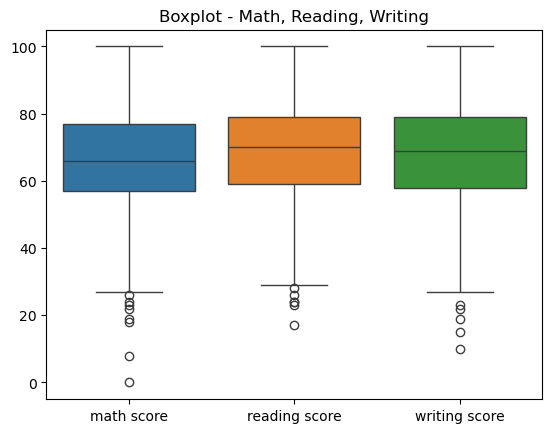

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Mean ---")
print(df[num_cols].mean())

print("\n--- Median ---")
print(df[num_cols].median())

print("\n--- Standard Deviation ---")
print(df[num_cols].std())

print("\n--- Quartiles ---")
print(df[num_cols].quantile([0.25, 0.5, 0.75]))

num_cols = df.select_dtypes(include='number').columns
print(num_cols)


plt.suptitle("Score Distribution")
plt.tight_layout()
plt.show()

sns.boxplot(data=df[num_cols])
plt.title("Boxplot - Math, Reading, Writing")
plt.show()

# Create Calculated Features - Total, Average, Percentage

In [48]:
df['Total Score'] = df['math score'] + df['reading score'] + df['writing score']

df['Average Score'] = df['Total Score'] / 3

df['Percentage'] = (df['Total Score'] / 300) * 100

print(df.head())

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  \
0                    none          72             72             74   
1               completed          69             90             88   
2                    none          90             95             93   
3                    none          47             57             44   
4                    none          76             78             75   

   Total Score  Average Score  Percentage  
0          218      72.666667   72.666667  
1          247      82.333333   82.333333  
2          278      

#  Race / Ethnicity analysis

In [59]:
race_analysis = df.groupby('race/ethnicity')[
    ['math score', 'reading score', 'writing score']
].mean()

print(race_analysis)

                math score  reading score  writing score
race/ethnicity                                          
group A          61.629213      64.674157      62.674157
group B          63.452632      67.352632      65.600000
group C          64.463950      69.103448      67.827586
group D          67.362595      70.030534      70.145038
group E          73.821429      73.028571      71.407143


# Gender equality analysis

In [60]:
gender_analysis = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

print(gender_analysis)

        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


# Overall student performance

In [62]:
print("Average Maths Score:", df['math score'].mean())

print("Average Reading Score:", df['reading score'].mean())

print("Average Writing Score:", df['writing score'].mean())

print("Overall Average Score:", df['Average Score'].mean())

Average Maths Score: 66.089
Average Reading Score: 69.169
Average Writing Score: 68.054
Overall Average Score: 67.77066666666666


# DATA VISUALIZATION

# Gender Performance

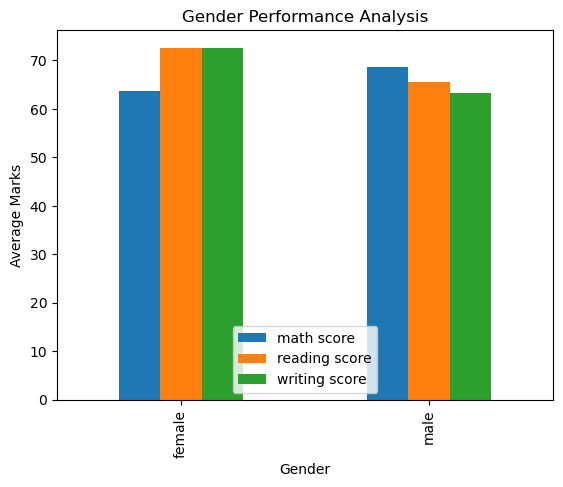

In [61]:
gender_analysis.plot(kind='bar')

plt.title('Gender Performance Analysis')
plt.xlabel('Gender')
plt.ylabel('Average Marks')
plt.show()

# Race / Ethnicity Performance

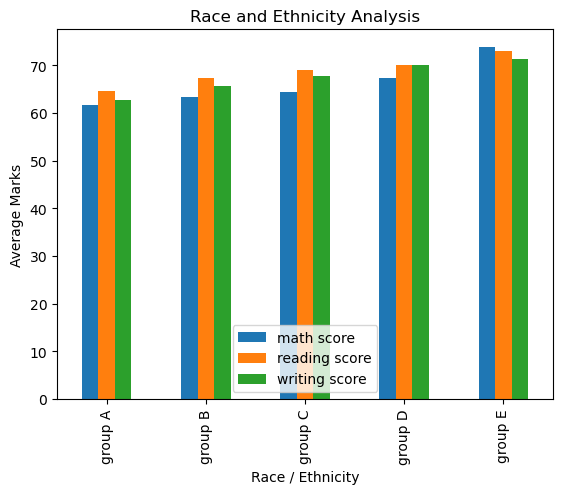

In [63]:
race_analysis.plot(kind='bar')

plt.title('Race and Ethnicity Analysis')
plt.xlabel('Race / Ethnicity')
plt.ylabel('Average Marks')
plt.show()

# Outcomes & Demographic Equality Analysis

### 1. Introduction
This project analyses students' academic performance based on demographic factors using Python.

### 2. Objective
- To analyse student performance.
- To compare male and female students.
- To study parental education and academic results.
- To analyse lunch type and test preparation effects.
- To identify performance differences among demographic groups.

### 3. Dataset Description
Dataset: StudentsPerformance.csv

- Total Records: 1000
- Total Columns: 8
- Features: Gender, Race/Ethnicity, Parental Education, Lunch, Test Preparation, Math Score, Reading Score and Writing Score.

### 4. Tools Used
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

### 5. Data Analysis
- Data cleaning and preprocessing.
- Total and average score calculation.
- Gender performance comparison.
- Race and ethnicity analysis.
- Parental education analysis.
- Lunch and test preparation analysis.
- Pass and fail analysis.

### 6. Visualization
Bar charts and pie charts were used to represent student performance and demographic differences.

### 7. Conclusion
This project helps analyse students' academic performance and understand differences among demographic groups. It provides useful insights into educational outcomes and equality using Python data analysis techniques.